In [1]:

from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import csv, json, random, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)
import timm

# 1. Reproducibility
SEED = 43

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Project paths
DATA_DIR = Path.cwd()
SPLIT_FILE = DATA_DIR / "dataset_split.csv"

MODEL_NAME = "tiny_vit_21m_224.in1k"

# 3. Existing fine-tuned model
BASELINE_CHECKPOINT = (
    DATA_DIR
    / "results"
    / "tinyvit_21m_finetune"
    / "checkpoints"
    / "tinyvit_21m_finetuned_best.pth"
)

# 4. Separate results for MIL experiment
RESULTS_DIR = (
    DATA_DIR / "results" / "tinyvit_21m_dual_attention_mil"
)

CACHE_DIR = RESULTS_DIR / "cache"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PLOTS_DIR = RESULTS_DIR / "plots"

for folder in (
    RESULTS_DIR, CACHE_DIR, CHECKPOINT_DIR, PLOTS_DIR
):
    folder.mkdir(parents=True, exist_ok=True)

# 5. Device
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

# 6. Original class mapping
CLASSES = ["Brittle", "Ductile", "Mixed"]

class_to_idx = {
    label: idx for idx, label in enumerate(CLASSES)
}

# 7. Verify required files
assert SPLIT_FILE.is_file(), (
    f"Missing split file: {SPLIT_FILE}"
)

assert BASELINE_CHECKPOINT.is_file(), (
    f"Missing checkpoint: {BASELINE_CHECKPOINT}"
)

# 8. Print configuration
print("Project:", DATA_DIR)
print("Device:", DEVICE)
print("Model:", MODEL_NAME)
print("Source checkpoint:", BASELINE_CHECKPOINT)
print("New results:", RESULTS_DIR)


Project: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database
Device: mps
Model: tiny_vit_21m_224.in1k
Source checkpoint: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_finetune/checkpoints/tinyvit_21m_finetuned_best.pth
New results: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_dual_attention_mil


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# 1. Load the original dataset split
with open(SPLIT_FILE, "r", encoding="utf-8-sig") as file:
    split_records = list(csv.DictReader(file))

# 2. Separate training, validation and test records
train_records = [
    r for r in split_records if r["split"] == "train"
]

val_records = [
    r for r in split_records if r["split"] == "validation"
]

test_records = [
    r for r in split_records if r["split"] == "test"
]

# 3. Verify original dataset sizes
assert (
    len(train_records),
    len(val_records),
    len(test_records)
) == (1402, 280, 279)

# 4. Verify no filename-derived group overlap
train_groups = {r["group"] for r in train_records}
val_groups = {r["group"] for r in val_records}
test_groups = {r["group"] for r in test_records}

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# 5. Calculate original class weights
train_counts = Counter(
    r["label"] for r in train_records
)

num_samples = len(train_records)
num_classes = len(CLASSES)

class_weights = torch.tensor(
    [
        num_samples / (num_classes * train_counts[label])
        for label in CLASSES
    ],
    dtype=torch.float32,
    device=DEVICE
)

# 6. Display dataset distribution
for name, records in [
    ("Train", train_records),
    ("Validation", val_records),
    ("Test", test_records)
]:
    counts = Counter(r["label"] for r in records)

    mixed_groups = len({
        r["group"]
        for r in records
        if r["label"] == "Mixed"
    })

    print(
        f"{name}: {len(records)} images | "
        f"Class counts: {dict(counts)} | "
        f"Mixed groups: {mixed_groups}"
    )

# 7. Display and verify weights
print("\nCLASS WEIGHTS")
print("-" * 45)

for label, weight in zip(CLASSES, class_weights):
    print(f"{label}: {weight.item():.4f}")

assert torch.allclose(
    class_weights.cpu(),
    torch.tensor([0.7934352, 0.6572902, 4.5816994]),
    rtol=1e-5,
    atol=1e-5
)

print("\nDataset verification successful.")


Train: 1402 images | Class counts: {'Brittle': 589, 'Ductile': 711, 'Mixed': 102} | Mixed groups: 41
Validation: 280 images | Class counts: {'Brittle': 117, 'Ductile': 142, 'Mixed': 21} | Mixed groups: 5
Test: 279 images | Class counts: {'Brittle': 116, 'Ductile': 143, 'Mixed': 20} | Mixed groups: 7

CLASS WEIGHTS
---------------------------------------------
Brittle: 0.7934
Ductile: 0.6573
Mixed: 4.5817

Dataset verification successful.


In [3]:

# 1. Recreate the original TinyViT-21M architecture
backbone = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=3
)

# 2. Load existing fine-tuned checkpoint
source_ckpt = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

assert source_ckpt.get("model_name", MODEL_NAME) == MODEL_NAME
assert source_ckpt.get("class_to_idx", class_to_idx) == class_to_idx

backbone.load_state_dict(
    source_ckpt["model_state_dict"],
    strict=True
)

# 3. Freeze every parameter
for p in backbone.parameters():
    p.requires_grad = False

backbone = backbone.to(DEVICE)
backbone.eval()

# 4. Verify model parameters
total_params = sum(
    p.numel() for p in backbone.parameters()
)

trainable_params = sum(
    p.numel()
    for p in backbone.parameters()
    if p.requires_grad
)

print("Loaded checkpoint epoch:",
      source_ckpt.get("epoch", "not recorded"))

print("Backbone parameters:", f"{total_params:,}")
print("Trainable parameters:", trainable_params)
print("Classifier input features:", backbone.head.fc.in_features)

assert trainable_params == 0

# 5. Extract features BEFORE the classification layer
@torch.inference_mode()
def extract_embeddings(image_batch):

    spatial = backbone.forward_features(image_batch)

    pooled = backbone.forward_head(
        spatial,
        pre_logits=True
    )

    assert pooled.ndim == 2
    assert pooled.shape[1] == backbone.head.fc.in_features

    return pooled

# 6. Verify feature extraction with a dummy image
dummy = torch.zeros(
    1, 3, 224, 224,
    device=DEVICE
)

embedding = extract_embeddings(dummy)

FEATURE_DIM = embedding.shape[1]

assert FEATURE_DIM == 576

print("\nFEATURE EXTRACTION")
print("-" * 50)
print("Input shape:", tuple(dummy.shape))
print("Embedding shape:", tuple(embedding.shape))
print("Feature dimension:", FEATURE_DIM)
print("Backbone frozen:", trainable_params == 0)
print("\nCell 3 verification successful.")


Loaded checkpoint epoch: 3
Backbone parameters: 20,623,299
Trainable parameters: 0
Classifier input features: 576

FEATURE EXTRACTION
--------------------------------------------------
Input shape: (1, 3, 224, 224)
Embedding shape: (1, 576)
Feature dimension: 576
Backbone frozen: True

Cell 3 verification successful.


Original file: 100Cr6_AR_05_11.png
MIL bag tensor: (10, 3, 224, 224)


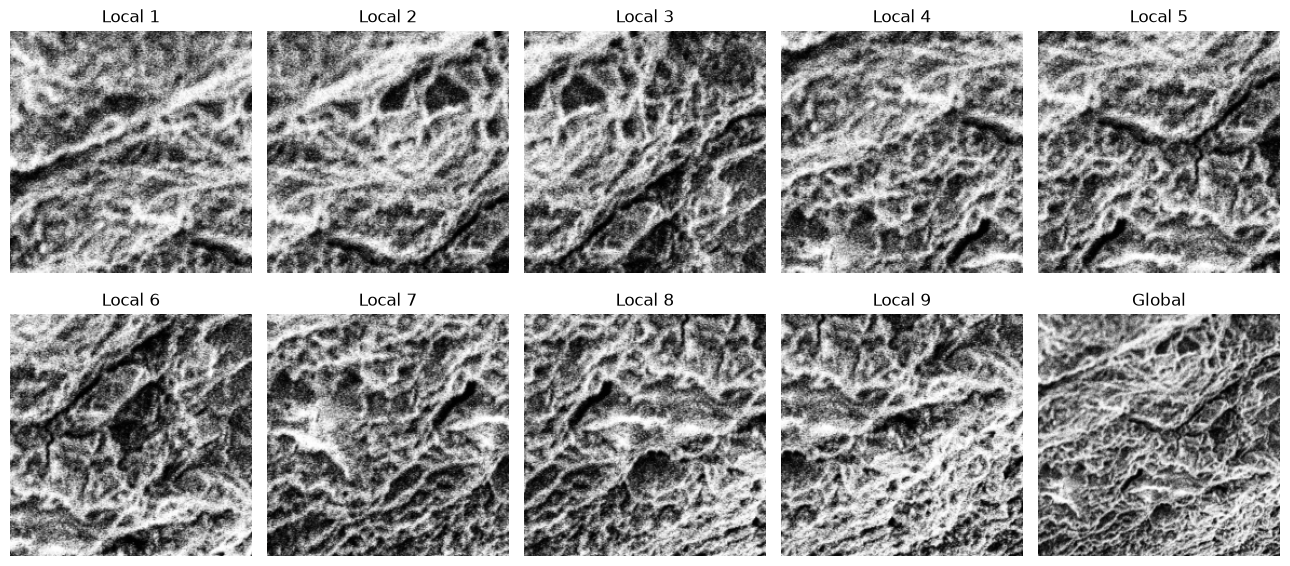

In [4]:

# 1. ImageNet normalization — unchanged
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# 2. Patch configuration
PATCH_SIZE = 224
CANVAS_SIZE = 448

# 50% overlap between adjacent patches
PATCH_STARTS = (0, 112, 224)

# 9 regional crops + 1 global view
N_PATCHES = 10

PATCH_BATCH_SIZE = 16

# Same horizontal/vertical flip types as before
TRAIN_VARIANTS = (
    "none",
    "hflip",
    "vflip",
    "hvflip"
)

# 3. Original normalization
patch_to_tensor = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# 4. Create ten views of one SEM image
def make_bag(image, variant="none"):

    image = image.convert("RGB")

    # Optional flips for training
    if variant in ("hflip", "hvflip"):
        image = ImageOps.mirror(image)

    if variant in ("vflip", "hvflip"):
        image = ImageOps.flip(image)

    # Working image for regional crops
    working = image.resize(
        (CANVAS_SIZE, CANVAS_SIZE),
        Image.Resampling.BILINEAR
    )

    # Extract nine overlapping regions
    crops = [
        working.crop((
            x, y,
            x + PATCH_SIZE,
            y + PATCH_SIZE
        ))
        for y in PATCH_STARTS
        for x in PATCH_STARTS
    ]

    # Add the complete image as the tenth view
    global_view = image.resize(
        (PATCH_SIZE, PATCH_SIZE),
        Image.Resampling.BILINEAR
    )

    crops.append(global_view)

    assert len(crops) == N_PATCHES

    return torch.stack([
        patch_to_tensor(crop)
        for crop in crops
    ], dim=0)


# 5. Test with one original training image
sample_row = train_records[0]

sample_path = (
    DATA_DIR
    / sample_row["label"]
    / sample_row["filename"]
)

assert sample_path.is_file(), (
    f"Missing SEM image: {sample_path}"
)

with Image.open(sample_path) as img:
    sample_bag = make_bag(img, variant="none")

assert sample_bag.shape == (
    10, 3, 224, 224
)

print("Original file:", sample_row["filename"])
print("MIL bag tensor:", tuple(sample_bag.shape))


# 6. Reverse normalization for visualization
def tensor_as_image(x):

    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)

    return (
        (x.cpu() * std + mean)
        .clamp(0, 1)
        .permute(1, 2, 0)
        .numpy()
    )


# 7. Plot all ten views
fig, axes = plt.subplots(
    2, 5,
    figsize=(13, 6)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        tensor_as_image(sample_bag[i])
    )

    ax.set_title(
        "Global" if i == 9
        else f"Local {i + 1}"
    )

    ax.axis("off")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "patch_grid_example.png",
    dpi=160
)

plt.show()


In [5]:

# 1. Extract and cache features for one dataset split
def cache_one_split_variant(records, split_name, variant):

    out_path = (
        CACHE_DIR
        / f"{split_name}_{variant}_features.pt"
    )

    expected_names = [
        r["filename"] for r in records
    ]

    # Reuse existing cache if already generated
    if out_path.exists():

        data = torch.load(
            out_path,
            map_location="cpu",
            weights_only=True
        )

        assert data["filenames"] == expected_names

        assert data["features"].shape == (
            len(records), N_PATCHES, FEATURE_DIM
        )

        print(f"Reusing {out_path.name}")

        return data["features"].float()

    features = []
    t0 = time.perf_counter()

    backbone.eval()

    # 2. Process every image
    for idx, row in enumerate(records):

        path = (
            DATA_DIR
            / row["label"]
            / row["filename"]
        )

        with Image.open(path) as img:
            bag = make_bag(img, variant)

        # 3. Pass image regions through frozen TinyViT
        patch_vectors = []

        for batch in bag.split(
            PATCH_BATCH_SIZE, dim=0
        ):

            z = extract_embeddings(
                batch.to(DEVICE)
            ).cpu().float()

            patch_vectors.append(z)

        # Shape: (10, 576)
        features.append(
            torch.cat(patch_vectors, dim=0)
        )

        # Progress tracking
        if (
            (idx + 1) % 100 == 0
            or idx + 1 == len(records)
        ):
            print(
                f"{split_name}/{variant}: "
                f"{idx + 1}/{len(records)} images"
            )

    # 4. Combine all image features
    features = torch.stack(
        features, dim=0
    ).contiguous()

    assert features.shape == (
        len(records), N_PATCHES, FEATURE_DIM
    )

    assert torch.isfinite(features).all()

    # 5. Save features to a separate cache
    torch.save(
        {
            "features": features,
            "filenames": expected_names,
            "variant": variant,
            "feature_dim": FEATURE_DIM,
            "patch_count": N_PATCHES,
            "checkpoint_path": str(
                BASELINE_CHECKPOINT
            )
        },
        out_path
    )

    print(
        f"Saved {out_path.name}: "
        f"{tuple(features.shape)}"
    )

    return features


# 6. Training features: same four flip combinations
train_feature_variants = [
    cache_one_split_variant(
        train_records,
        "train",
        variant
    )
    for variant in TRAIN_VARIANTS
]

# 7. Validation features: no augmentation
val_features = cache_one_split_variant(
    val_records,
    "validation",
    "none"
)

# 8. Verify output
print("\nTRAIN FEATURE SHAPES")

for variant, features in zip(
    TRAIN_VARIANTS,
    train_feature_variants
):
    print(variant, tuple(features.shape))

print("\nVALIDATION FEATURE SHAPE")
print(tuple(val_features.shape))

print("\nCell 5 completed successfully.")


train/none: 100/1402 images
train/none: 200/1402 images
train/none: 300/1402 images
train/none: 400/1402 images
train/none: 500/1402 images
train/none: 600/1402 images
train/none: 700/1402 images
train/none: 800/1402 images
train/none: 900/1402 images
train/none: 1000/1402 images
train/none: 1100/1402 images
train/none: 1200/1402 images
train/none: 1300/1402 images
train/none: 1400/1402 images
train/none: 1402/1402 images
Saved train_none_features.pt: (1402, 10, 576)
train/hflip: 100/1402 images
train/hflip: 200/1402 images
train/hflip: 300/1402 images
train/hflip: 400/1402 images
train/hflip: 500/1402 images
train/hflip: 600/1402 images
train/hflip: 700/1402 images
train/hflip: 800/1402 images
train/hflip: 900/1402 images
train/hflip: 1000/1402 images
train/hflip: 1100/1402 images
train/hflip: 1200/1402 images
train/hflip: 1300/1402 images
train/hflip: 1400/1402 images
train/hflip: 1402/1402 images
Saved train_hflip_features.pt: (1402, 10, 576)
train/vflip: 100/1402 images
train/vflip

In [6]:

# 1. Convert original labels into two evidence targets
BINARY_TARGETS = torch.tensor([
    [1.0, 0.0],  # Brittle only
    [0.0, 1.0],  # Ductile only
    [1.0, 1.0],  # Mixed: both
], dtype=torch.float32, device=DEVICE)


# 2. Define the new Dual-Attention MIL architecture
class DualAttentionMIL(nn.Module):

    def __init__(self, feature_dim=576, attention_hidden=128):
        super().__init__()

        # Attention branch for brittle features
        self.brittle_attention = nn.Sequential(
            nn.Linear(feature_dim, attention_hidden),
            nn.Tanh(),
            nn.Linear(attention_hidden, 1)
        )

        # Attention branch for ductile features
        self.ductile_attention = nn.Sequential(
            nn.Linear(feature_dim, attention_hidden),
            nn.Tanh(),
            nn.Linear(attention_hidden, 1)
        )

        # Separate evidence prediction heads
        self.brittle_head = nn.Linear(feature_dim, 1)
        self.ductile_head = nn.Linear(feature_dim, 1)

    def forward(self, x):

        # x shape: (batch, 10, 576)

        # 3. Calculate attention weights for each region
        a_b = torch.softmax(
            self.brittle_attention(x).squeeze(-1),
            dim=1
        )

        a_d = torch.softmax(
            self.ductile_attention(x).squeeze(-1),
            dim=1
        )

        # 4. Combine regional features using attention
        b_features = (
            x * a_b.unsqueeze(-1)
        ).sum(dim=1)

        d_features = (
            x * a_d.unsqueeze(-1)
        ).sum(dim=1)

        # 5. Predict evidence for each mechanism
        b_logit = self.brittle_head(b_features)
        d_logit = self.ductile_head(d_features)

        logits = torch.cat(
            [b_logit, d_logit],
            dim=1
        )

        attention = torch.stack(
            [a_b, a_d],
            dim=1
        )

        return logits, attention


# 6. Convert two evidence scores to three-class probabilities
def class_probabilities(binary_logits):

    p = torch.sigmoid(binary_logits)

    pb = p[:, 0]
    pd = p[:, 1]

    joint = torch.stack([
        pb * (1 - pd),       # Brittle only
        (1 - pb) * pd,       # Ductile only
        pb * pd              # Mixed: both
    ], dim=1)

    # Normalize, assuming at least one mechanism is present
    return joint / joint.sum(
        dim=1, keepdim=True
    ).clamp_min(1e-8)


# 7. Initialize the new MIL model
mil_model = DualAttentionMIL(
    feature_dim=FEATURE_DIM,
    attention_hidden=128
).to(DEVICE)

head_trainable = sum(
    p.numel()
    for p in mil_model.parameters()
    if p.requires_grad
)

print("Frozen TinyViT feature width:", FEATURE_DIM)
print(
    "Trainable new MIL-head parameters:",
    f"{head_trainable:,}"
)


# 8. Test the architecture using dummy features
fake_bags = torch.randn(
    2, N_PATCHES, FEATURE_DIM,
    device=DEVICE
)

logits, attention = mil_model(fake_bags)

probs = class_probabilities(logits)


# 9. Verify shapes
assert logits.shape == (2, 2)
assert attention.shape == (2, 2, N_PATCHES)
assert probs.shape == (2, 3)

assert torch.allclose(
    attention.sum(dim=2),
    torch.ones(2, 2, device=DEVICE),
    atol=1e-5
)

assert torch.allclose(
    probs.sum(dim=1),
    torch.ones(2, device=DEVICE),
    atol=1e-5
)

print("\nMODEL VERIFICATION")
print("-" * 50)
print("Input:", tuple(fake_bags.shape))
print("Evidence logits:", tuple(logits.shape))
print("Attention weights:", tuple(attention.shape))
print("Class probabilities:", tuple(probs.shape))
print("\nCell 6 verification successful.")


Frozen TinyViT feature width: 576
Trainable new MIL-head parameters: 149,124

MODEL VERIFICATION
--------------------------------------------------
Input: (2, 10, 576)
Evidence logits: (2, 2)
Attention weights: (2, 2, 10)
Class probabilities: (2, 3)

Cell 6 verification successful.


In [7]:

# 1. Dataset for cached TinyViT features
class CachedBagDataset(Dataset):

    def __init__(
        self,
        feature_variants,
        records,
        augment=False
    ):

        # Shape: (images, variants, patches, features)
        self.features = torch.stack(
            feature_variants,
            dim=1
        )

        self.labels = torch.tensor(
            [
                class_to_idx[r["label"]]
                for r in records
            ],
            dtype=torch.long
        )

        self.augment = augment

        assert len(self.features) == len(self.labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        # Randomly choose one of the four flip variants
        if self.augment:
            k = torch.randint(
                self.features.shape[1],
                (1,)
            ).item()
        else:
            k = 0

        return (
            self.features[idx, k],
            self.labels[idx]
        )


# 2. Create training and validation datasets
train_dataset = CachedBagDataset(
    train_feature_variants,
    train_records,
    augment=True
)

val_dataset = CachedBagDataset(
    [val_features],
    val_records,
    augment=False
)


# 3. DataLoaders — original batch size
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


# 4. Class-weighted binary cross-entropy
def weighted_binary_loss(logits, labels):

    # Convert original labels to two evidence targets
    targets = BINARY_TARGETS[labels]

    # Calculate binary loss for both mechanisms
    two_losses = F.binary_cross_entropy_with_logits(
        logits,
        targets,
        reduction="none"
    ).mean(dim=1)

    # Preserve original image-level class weights
    weights = class_weights[labels]

    return (
        (two_losses * weights).sum()
        / weights.sum()
    )


# 5. Reinitialize MIL head with a fixed seed
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

mil_model = DualAttentionMIL(
    feature_dim=FEATURE_DIM,
    attention_hidden=128
).to(DEVICE)


# 6. Original classifier-head learning parameters
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 30
PATIENCE = 4

optimizer = torch.optim.AdamW(
    mil_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

checkpoint_path = (
    CHECKPOINT_DIR
    / "tinyvit21m_dual_attention_mil_best.pth"
)


# 7. Diagnostic forward and backward pass
bags, labels = next(iter(train_loader))

bags = bags.to(DEVICE)
labels = labels.to(DEVICE)

optimizer.zero_grad(set_to_none=True)

logits, attention = mil_model(bags)

loss = weighted_binary_loss(
    logits,
    labels
)

loss.backward()


# 8. Verify all trainable parameters receive gradients
assert all(
    p.grad is not None
    and torch.isfinite(p.grad).all()
    for p in mil_model.parameters()
)

# No optimizer.step(): parameters remain unchanged
optimizer.zero_grad(set_to_none=True)


# 9. Print verification
print("TRAINING CONFIGURATION")
print("-" * 55)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)

print("\nDIAGNOSTIC")
print("-" * 55)

print("Input bags:", tuple(bags.shape))
print("Evidence logits:", tuple(logits.shape))
print("Loss:", round(loss.item(), 5))

print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in mil_model.parameters()):,}"
)

print("\nCell 7 verification successful.")


TRAINING CONFIGURATION
-------------------------------------------------------
Training images: 1402
Validation images: 280
Batch size: 16
Learning rate: 0.0001
Weight decay: 0.0001
Maximum epochs: 30
Early stopping patience: 4

DIAGNOSTIC
-------------------------------------------------------
Input bags: (16, 10, 576)
Evidence logits: (16, 2)
Loss: 0.69438
Trainable parameters: 149,124

Cell 7 verification successful.


In [8]:

import time
from sklearn.metrics import precision_score

# 1. Initialize training history
history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "val_mixed_precision": [],
    "val_mixed_recall": [],
    "val_mixed_f1": [],
    "epoch_time": []
}

best_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

print("TRAINING TINYVIT-21M — DUAL ATTENTION MIL")
print("=" * 85)

print("Architecture:", MODEL_NAME)
print("Device:", DEVICE)
print("Frozen backbone: True")
print("Trainable parameters:", f"{head_trainable:,}")
print("Maximum epochs:", MAX_EPOCHS)
print("Selection metric: Validation macro-F1")
print()

# 2. Training loop
for epoch in range(MAX_EPOCHS):

    if DEVICE.type == "mps":
        torch.mps.synchronize()

    start_time = time.perf_counter()

    mil_model.train()

    total_train_loss = 0.0
    train_samples = 0

    # 3. Training batches
    for bags, labels in train_loader:

        bags = bags.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits, attention = mil_model(bags)

        loss = weighted_binary_loss(
            logits, labels
        )

        assert torch.isfinite(loss).item()

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            mil_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        batch_size = labels.size(0)

        total_train_loss += (
            loss.item() * batch_size
        )

        train_samples += batch_size

    train_loss = total_train_loss / train_samples

    # 4. Validation
    mil_model.eval()

    total_val_loss = 0.0
    val_samples = 0

    all_labels = []
    all_predictions = []

    with torch.inference_mode():

        for bags, labels in val_loader:

            bags = bags.to(DEVICE)
            labels_device = labels.to(DEVICE)

            logits, attention = mil_model(bags)

            loss = weighted_binary_loss(
                logits, labels_device
            )

            probabilities = class_probabilities(
                logits
            )

            predictions = probabilities.argmax(dim=1)

            batch_size = labels.size(0)

            total_val_loss += (
                loss.item() * batch_size
            )

            val_samples += batch_size

            all_labels.extend(
                labels.tolist()
            )

            all_predictions.extend(
                predictions.cpu().tolist()
            )

    val_loss = total_val_loss / val_samples

    # 5. Calculate validation metrics
    val_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    mixed_precision = precision_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    mixed_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    mixed_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    # 6. Record epoch duration
    if DEVICE.type == "mps":
        torch.mps.synchronize()

    epoch_time = time.perf_counter() - start_time

    # 7. Store training history
    history["train_loss"].append(float(train_loss))
    history["val_loss"].append(float(val_loss))
    history["val_accuracy"].append(float(val_accuracy))
    history["val_macro_f1"].append(float(val_macro_f1))
    history["val_mixed_precision"].append(float(mixed_precision))
    history["val_mixed_recall"].append(float(mixed_recall))
    history["val_mixed_f1"].append(float(mixed_f1))
    history["epoch_time"].append(float(epoch_time))

    # 8. Save best model based on validation macro-F1
    improved = val_macro_f1 > best_f1 + 1e-6

    if improved:

        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": {
                    k: v.detach().cpu().clone()
                    for k, v in mil_model.state_dict().items()
                },
                "model_name": MODEL_NAME,
                "feature_dim": FEATURE_DIM,
                "attention_hidden": 128,
                "n_patches": N_PATCHES,
                "val_macro_f1": float(val_macro_f1),
                "val_accuracy": float(val_accuracy),
                "val_mixed_f1": float(mixed_f1),
                "val_mixed_recall": float(mixed_recall),
                "source_checkpoint": str(
                    BASELINE_CHECKPOINT
                )
            },
            checkpoint_path
        )

    else:
        epochs_without_improvement += 1

    # 9. Print epoch metrics
    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.4f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Mixed P/R/F1: "
        f"{mixed_precision:.4f}/"
        f"{mixed_recall:.4f}/"
        f"{mixed_f1:.4f} | "
        f"Time: {epoch_time:.1f}s"
        + (" | BEST" if improved else "")
    )

    # 10. Early stopping
    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping after epoch {epoch + 1}"
        )

        break


# 11. Restore best checkpoint
best_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

mil_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

mil_model = mil_model.to(DEVICE)
mil_model.eval()

assert best_checkpoint["epoch"] == best_epoch

# 12. Save training history
history_path = RESULTS_DIR / "training_history.json"

with open(history_path, "w") as f:
    json.dump(history, f, indent=4)

# 13. Final summary
print("\nTRAINING COMPLETE")
print("=" * 65)

print("Best epoch:", best_epoch)
print(f"Best validation macro-F1: {best_f1:.4f}")

print(
    "Best validation Mixed F1:",
    f"{best_checkpoint['val_mixed_f1']:.4f}"
)

print("Saved checkpoint:", checkpoint_path)
print("Saved history:", history_path)

print("\nCell 8 completed successfully.")


TRAINING TINYVIT-21M — DUAL ATTENTION MIL
Architecture: tiny_vit_21m_224.in1k
Device: mps
Frozen backbone: True
Trainable parameters: 149,124
Maximum epochs: 30
Selection metric: Validation macro-F1

Epoch 01/30 | Train Loss: 0.5610 | Val Loss: 0.4181 | Accuracy: 0.6857 | Macro-F1: 0.5923 | Mixed P/R/F1: 0.0964/0.3810/0.1538 | Time: 0.5s | BEST
Epoch 02/30 | Train Loss: 0.3291 | Val Loss: 0.2511 | Accuracy: 0.8607 | Macro-F1: 0.7655 | Mixed P/R/F1: 0.3200/0.7619/0.4507 | Time: 0.2s | BEST
Epoch 03/30 | Train Loss: 0.2216 | Val Loss: 0.1653 | Accuracy: 0.9464 | Macro-F1: 0.8791 | Mixed P/R/F1: 0.6071/0.8095/0.6939 | Time: 0.2s | BEST
Epoch 04/30 | Train Loss: 0.1642 | Val Loss: 0.1135 | Accuracy: 0.9679 | Macro-F1: 0.9189 | Mixed P/R/F1: 0.7727/0.8095/0.7907 | Time: 0.2s | BEST
Epoch 05/30 | Train Loss: 0.1318 | Val Loss: 0.0917 | Accuracy: 0.9821 | Macro-F1: 0.9566 | Mixed P/R/F1: 0.8333/0.9524/0.8889 | Time: 0.2s | BEST
Epoch 06/30 | Train Loss: 0.1181 | Val Loss: 0.0761 | Accuracy: 0

BEST MIL CHECKPOINT
------------------------------------------------------------
Epoch: 8
Validation Macro-F1: 0.9644839006541135

VALIDATION COMPARISON

Original TinyViT-21M
Accuracy: 0.9929
Macro-F1: 0.9810
Mixed F1: 0.9500
              precision    recall  f1-score   support

     Brittle     1.0000    1.0000    1.0000       117
     Ductile     0.9861    1.0000    0.9930       142
       Mixed     1.0000    0.9048    0.9500        21

    accuracy                         0.9929       280
   macro avg     0.9954    0.9683    0.9810       280
weighted avg     0.9930    0.9929    0.9927       280


Dual-Attention MIL
Accuracy: 0.9857
Macro-F1: 0.9645
Mixed F1: 0.9091
              precision    recall  f1-score   support

     Brittle     0.9915    0.9915    0.9915       117
     Ductile     1.0000    0.9859    0.9929       142
       Mixed     0.8696    0.9524    0.9091        21

    accuracy                         0.9857       280
   macro avg     0.9537    0.9766    0.9645       

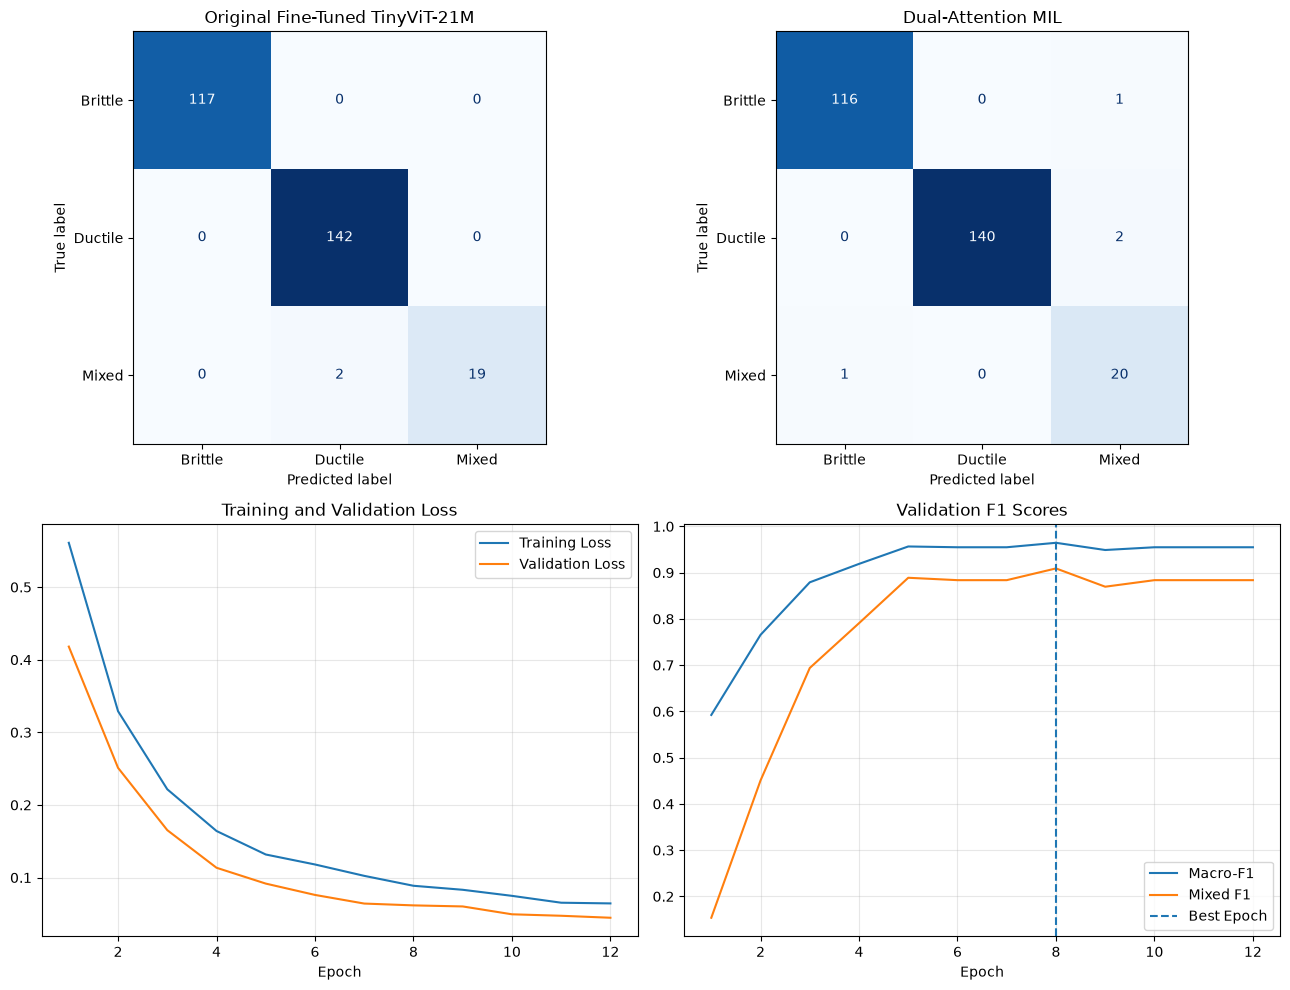


Saved audit: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_dual_attention_mil/validation_prediction_audit.csv
Saved plot: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_dual_attention_mil/plots/mil_vs_original_validation.png

Cell 9 completed successfully.


In [9]:

# 1. Load best MIL checkpoint
best_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

mil_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

mil_model.eval()
backbone.eval()

print("BEST MIL CHECKPOINT")
print("-" * 60)
print("Epoch:", best_checkpoint["epoch"])
print("Validation Macro-F1:",
      best_checkpoint["val_macro_f1"])


# 2. MIL validation predictions
y_true = []
mil_preds = []
mil_probs = []

with torch.inference_mode():

    for bags, labels in val_loader:

        logits, attention = mil_model(
            bags.to(DEVICE)
        )

        probs = class_probabilities(logits)

        y_true.extend(labels.tolist())
        mil_preds.extend(
            probs.argmax(dim=1).cpu().tolist()
        )

        mil_probs.extend(
            probs.cpu().tolist()
        )


# 3. Original TinyViT predictions
# The 10th cached view is the complete image.
# Its 576 features feed the original classifier.

original_preds = []

with torch.inference_mode():

    for start in range(
        0, len(val_features), BATCH_SIZE
    ):

        global_features = val_features[
            start:start + BATCH_SIZE, -1, :
        ].to(DEVICE)

        logits = backbone.head.fc(
            global_features
        )

        original_preds.extend(
            logits.argmax(dim=1).cpu().tolist()
        )


# 4. Verify alignment and original results
assert len(y_true) == 280
assert len(original_preds) == 280
assert len(mil_preds) == 280

assert y_true == [
    class_to_idx[r["label"]]
    for r in val_records
]

original_cm = confusion_matrix(
    y_true, original_preds, labels=[0, 1, 2]
)

mil_cm = confusion_matrix(
    y_true, mil_preds, labels=[0, 1, 2]
)

# Original fine-tuned checkpoint should reproduce
# the previously reported confusion matrix.
expected_original_cm = np.array([
    [117, 0, 0],
    [0, 142, 0],
    [0, 2, 19]
])

assert np.array_equal(
    original_cm, expected_original_cm
), (
    "Original predictions differ from the prior "
    "validation results. Verify cached global features."
)


# 5. Compare evaluation metrics
print("\nVALIDATION COMPARISON")
print("=" * 70)

for name, predictions in [
    ("Original TinyViT-21M", original_preds),
    ("Dual-Attention MIL", mil_preds)
]:

    acc = accuracy_score(y_true, predictions)

    macro = f1_score(
        y_true, predictions,
        average="macro",
        zero_division=0
    )

    mixed_f1 = f1_score(
        y_true, predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    print(f"\n{name}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Macro-F1: {macro:.4f}")
    print(f"Mixed F1: {mixed_f1:.4f}")

    print(classification_report(
        y_true, predictions,
        labels=[0, 1, 2],
        target_names=CLASSES,
        digits=4,
        zero_division=0
    ))


# 6. Prediction-level audit
audit_rows = []

for i, record in enumerate(val_records):

    actual = y_true[i]
    old = original_preds[i]
    new = mil_preds[i]

    if old != actual and new == actual:
        status = "Corrected"
    elif old == actual and new != actual:
        status = "New error"
    elif old != actual and new != actual:
        status = "Still wrong"
    else:
        status = "Correct"

    audit_rows.append({
        "filename": record["filename"],
        "group": record["group"],
        "actual": CLASSES[actual],
        "original": CLASSES[old],
        "mil": CLASSES[new],
        "status": status,
        "mil_confidence": max(mil_probs[i])
    })

audit = pd.DataFrame(audit_rows)

changed = audit[
    audit["status"] != "Correct"
].copy()

print("\nPREDICTION AUDIT")
print("=" * 70)

print(audit["status"].value_counts())

print("\nCORRECTED / MISCLASSIFIED IMAGES")
print(changed.to_string(index=False))


# 7. Save audit
audit_path = (
    RESULTS_DIR / "validation_prediction_audit.csv"
)

audit.to_csv(audit_path, index=False)


# 8. Plot confusion matrices and learning curves
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

ConfusionMatrixDisplay(
    original_cm,
    display_labels=CLASSES
).plot(
    ax=axes[0, 0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0, 0].set_title("Original Fine-Tuned TinyViT-21M")

ConfusionMatrixDisplay(
    mil_cm,
    display_labels=CLASSES
).plot(
    ax=axes[0, 1],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0, 1].set_title("Dual-Attention MIL")

epochs = np.arange(
    1, len(history["train_loss"]) + 1
)

axes[1, 0].plot(
    epochs, history["train_loss"],
    label="Training Loss"
)

axes[1, 0].plot(
    epochs, history["val_loss"],
    label="Validation Loss"
)

axes[1, 0].set_title("Training and Validation Loss")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(
    epochs, history["val_macro_f1"],
    label="Macro-F1"
)

axes[1, 1].plot(
    epochs, history["val_mixed_f1"],
    label="Mixed F1"
)

axes[1, 1].axvline(
    best_checkpoint["epoch"],
    linestyle="--",
    label="Best Epoch"
)

axes[1, 1].set_title("Validation F1 Scores")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()

plot_path = (
    PLOTS_DIR / "mil_vs_original_validation.png"
)

plt.savefig(plot_path, dpi=160)
plt.show()

print("\nSaved audit:", audit_path)
print("Saved plot:", plot_path)
print("\nCell 9 completed successfully.")


In [10]:

# CELL 10 — HELD-OUT TEST EVALUATION

# 1. Extract and cache test image features
# No augmentation and no training
test_features = cache_one_split_variant(
    test_records,
    "test",
    "none"
)

# 2. Create test dataset
test_dataset = CachedBagDataset(
    [test_features],
    test_records,
    augment=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

assert len(test_dataset) == 279

# 3. Freeze both models for evaluation
backbone.eval()
mil_model.eval()

test_true = []
original_test_preds = []
mil_test_preds = []
mil_test_probs = []

# 4. Evaluate both models on identical images
with torch.inference_mode():

    for bags, labels in test_loader:

        bags = bags.to(DEVICE)

        # Original TinyViT:
        # Use the global (10th) image view
        global_features = bags[:, -1, :]

        original_logits = backbone.head.fc(
            global_features
        )

        original_predictions = (
            original_logits.argmax(dim=1)
        )

        # Dual-Attention MIL:
        # Use all 10 image views
        mil_logits, attention = mil_model(bags)

        probabilities = class_probabilities(
            mil_logits
        )

        mil_predictions = probabilities.argmax(dim=1)

        test_true.extend(labels.tolist())

        original_test_preds.extend(
            original_predictions.cpu().tolist()
        )

        mil_test_preds.extend(
            mil_predictions.cpu().tolist()
        )

        mil_test_probs.extend(
            probabilities.cpu().tolist()
        )

# 5. Verify alignment
assert len(test_true) == 279

assert test_true == [
    class_to_idx[r["label"]]
    for r in test_records
]

# 6. Confirm original TinyViT test predictions
original_test_cm = confusion_matrix(
    test_true,
    original_test_preds,
    labels=[0, 1, 2]
)

expected_original_test_cm = np.array([
    [115, 0, 1],
    [0, 139, 4],
    [3, 3, 14]
])

assert np.array_equal(
    original_test_cm,
    expected_original_test_cm
), "Original TinyViT test results did not reproduce."

# 7. Calculate MIL confusion matrix
mil_test_cm = confusion_matrix(
    test_true,
    mil_test_preds,
    labels=[0, 1, 2]
)

# 8. Compare both models
test_results = {}

print("TINYVIT-21M — TEST COMPARISON")
print("=" * 70)

for name, predictions in [
    ("Original TinyViT", original_test_preds),
    ("Dual-Attention MIL", mil_test_preds)
]:

    acc = accuracy_score(test_true, predictions)

    macro = f1_score(
        test_true, predictions,
        average="macro",
        zero_division=0
    )

    mixed_f1 = f1_score(
        test_true, predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    print(f"\n{name}")
    print("-" * 60)
    print(f"Accuracy: {acc:.4f}")
    print(f"Macro-F1: {macro:.4f}")
    print(f"Mixed F1: {mixed_f1:.4f}")

    report = classification_report(
        test_true,
        predictions,
        labels=[0, 1, 2],
        target_names=CLASSES,
        digits=4,
        output_dict=True,
        zero_division=0
    )

    print(classification_report(
        test_true,
        predictions,
        labels=[0, 1, 2],
        target_names=CLASSES,
        digits=4,
        zero_division=0
    ))

    test_results[name] = {
        "accuracy": float(acc),
        "macro_f1": float(macro),
        "mixed_f1": float(mixed_f1),
        "classification_report": report
    }

# 9. Identify corrected and new errors
audit_rows = []

for i, record in enumerate(test_records):

    actual = test_true[i]
    old = original_test_preds[i]
    new = mil_test_preds[i]

    if old != actual and new == actual:
        status = "Corrected"
    elif old == actual and new != actual:
        status = "New error"
    elif old != actual and new != actual:
        status = "Still wrong"
    else:
        status = "Correct"

    audit_rows.append({
        "filename": record["filename"],
        "group": record["group"],
        "actual": CLASSES[actual],
        "original": CLASSES[old],
        "mil": CLASSES[new],
        "status": status,
        "mil_confidence": max(mil_test_probs[i])
    })

test_audit = pd.DataFrame(audit_rows)

print("\nTEST PREDICTION AUDIT")
print("=" * 70)

print(test_audit["status"].value_counts())

print("\nMISCLASSIFIED / CORRECTED IMAGES")

print(
    test_audit[
        test_audit["status"] != "Correct"
    ].to_string(index=False)
)

# 10. Save test results
test_results_path = (
    RESULTS_DIR / "test_comparison.json"
)

test_audit_path = (
    RESULTS_DIR / "test_prediction_audit.csv"
)

with open(test_results_path, "w") as f:
    json.dump(test_results, f, indent=4)

test_audit.to_csv(
    test_audit_path,
    index=False
)

print("\nSaved:", test_results_path)
print("Saved:", test_audit_path)
print("\nCell 10 completed successfully.")


test/none: 100/279 images
test/none: 200/279 images
test/none: 279/279 images
Saved test_none_features.pt: (279, 10, 576)
TINYVIT-21M — TEST COMPARISON

Original TinyViT
------------------------------------------------------------
Accuracy: 0.9606
Macro-F1: 0.8921
Mixed F1: 0.7179
              precision    recall  f1-score   support

     Brittle     0.9746    0.9914    0.9829       116
     Ductile     0.9789    0.9720    0.9754       143
       Mixed     0.7368    0.7000    0.7179        20

    accuracy                         0.9606       279
   macro avg     0.8968    0.8878    0.8921       279
weighted avg     0.9597    0.9606    0.9601       279


Dual-Attention MIL
------------------------------------------------------------
Accuracy: 0.9498
Macro-F1: 0.8811
Mixed F1: 0.6957
              precision    recall  f1-score   support

     Brittle     0.9748    1.0000    0.9872       116
     Ductile     0.9925    0.9301    0.9603       143
       Mixed     0.6154    0.8000    0.695

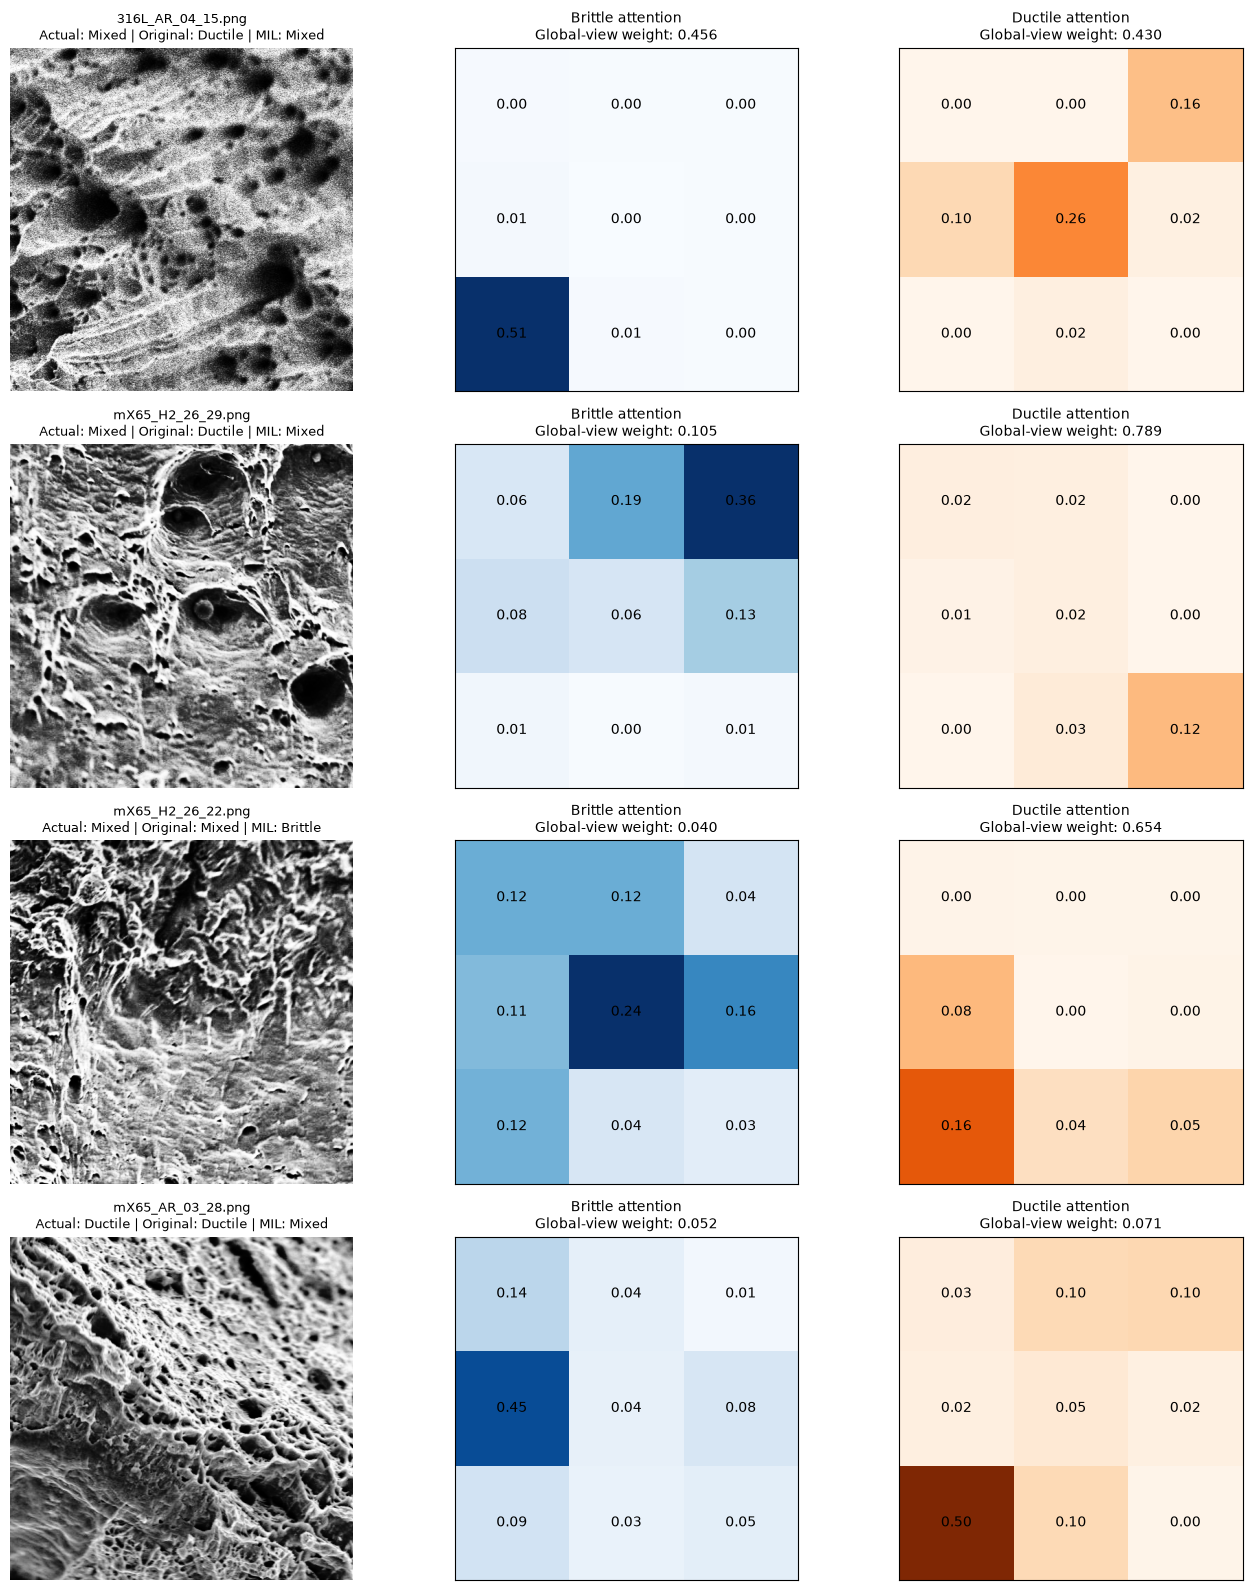


DUAL ATTENTION CASE STUDY
         filename  actual original_prediction mil_prediction  brittle_evidence  ductile_evidence  mixed_probability  brittle_global_attention  ductile_global_attention
316L_AR_04_15.png   Mixed             Ductile          Mixed            0.6742            0.9899             0.6696                    0.4559                    0.4303
mX65_H2_26_29.png   Mixed             Ductile          Mixed            0.5082            0.9977             0.5076                    0.1051                    0.7886
mX65_H2_26_22.png   Mixed               Mixed        Brittle            0.9847            0.3883             0.3860                    0.0400                    0.6538
mX65_AR_03_28.png Ductile             Ductile          Mixed            0.5541            0.9714             0.5452                    0.0519                    0.0705

Saved plot: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_du

In [11]:

# CELL 11 — DUAL ATTENTION VISUALIZATION

# 1. Select validation images
case_files = [
    "316L_AR_04_15.png",    # Corrected
    "mX65_H2_26_29.png",   # Corrected
    "mX65_H2_26_22.png",   # New error
    "mX65_AR_03_28.png"    # New error
]

val_lookup = {
    row["filename"]: i
    for i, row in enumerate(val_records)
}

assert all(
    name in val_lookup for name in case_files
)

mil_model.eval()
backbone.eval()

fig, axes = plt.subplots(
    len(case_files), 3,
    figsize=(14, 4 * len(case_files))
)

audit_rows = []

for row_idx, filename in enumerate(case_files):

    idx = val_lookup[filename]
    record = val_records[idx]

    # 2. Load cached regional features
    features = val_features[
        idx:idx + 1
    ].to(DEVICE)

    # 3. Get predictions and attention
    with torch.inference_mode():

        logits, attention = mil_model(features)

        probabilities = class_probabilities(logits)

        evidence = torch.sigmoid(logits)

        original_logits = backbone.head.fc(
            features[:, -1, :]
        )

    weights = attention[0].cpu().numpy()

    evidence = evidence[0].cpu().numpy()
    probabilities = probabilities[0].cpu().numpy()

    original_pred = CLASSES[
        original_logits.argmax(dim=1).item()
    ]

    mil_pred = CLASSES[
        int(probabilities.argmax())
    ]

    # 4. Display original SEM image
    image_path = (
        DATA_DIR
        / record["label"]
        / filename
    )

    with Image.open(image_path) as image:
        original_image = image.convert("L").copy()

    axes[row_idx, 0].imshow(
        original_image,
        cmap="gray"
    )

    axes[row_idx, 0].set_title(
        f"{filename}\n"
        f"Actual: {record['label']} | "
        f"Original: {original_pred} | "
        f"MIL: {mil_pred}",
        fontsize=9
    )

    axes[row_idx, 0].axis("off")

    # 5. Plot attention maps
    vmax = max(
        0.15,
        float(weights[:, :9].max())
    )

    for branch_idx, title in enumerate(
        ["Brittle attention", "Ductile attention"]
    ):

        ax = axes[row_idx, branch_idx + 1]

        # Nine regional weights arranged as 3x3
        local_weights = weights[
            branch_idx, :9
        ].reshape(3, 3)

        ax.imshow(
            local_weights,
            cmap="Blues" if branch_idx == 0 else "Oranges",
            vmin=0,
            vmax=vmax
        )

        # Display weight in each region
        for y in range(3):
            for x in range(3):

                ax.text(
                    x, y,
                    f"{local_weights[y, x]:.2f}",
                    ha="center",
                    va="center",
                    fontsize=10,
                    color="black"
                )

        global_weight = weights[branch_idx, 9]

        ax.set_title(
            f"{title}\n"
            f"Global-view weight: {global_weight:.3f}",
            fontsize=10
        )

        ax.set_xticks([])
        ax.set_yticks([])

    # 6. Save numerical evidence
    audit_rows.append({
        "filename": filename,
        "actual": record["label"],
        "original_prediction": original_pred,
        "mil_prediction": mil_pred,
        "brittle_evidence": float(evidence[0]),
        "ductile_evidence": float(evidence[1]),
        "mixed_probability": float(probabilities[2]),
        "brittle_global_attention": float(weights[0, 9]),
        "ductile_global_attention": float(weights[1, 9])
    })

plt.tight_layout()

plot_path = (
    PLOTS_DIR / "dual_attention_case_study.png"
)

plt.savefig(
    plot_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# 7. Display the numerical summary
attention_audit = pd.DataFrame(audit_rows)

print("\nDUAL ATTENTION CASE STUDY")
print("=" * 80)

print(
    attention_audit.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

audit_path = (
    RESULTS_DIR / "attention_case_study.csv"
)

attention_audit.to_csv(
    audit_path,
    index=False
)

print("\nSaved plot:", plot_path)
print("Saved audit:", audit_path)

print("\nCell 11 completed successfully.")


VALIDATION — EVIDENCE ANALYSIS

AVERAGE EVIDENCE BY ACTUAL CLASS
         brittle_evidence  ductile_evidence  mixed_probability
actual                                                        
Brittle            0.9848            0.0503             0.0499
Ductile            0.1183            0.9861             0.1173
Mixed              0.8993            0.9335             0.8370

MISCLASSIFIED IMAGES
-----------------------------------------------------------------
           filename  actual predicted  brittle_evidence  ductile_evidence  mixed_probability
100Cr6_AR_06_10.png Brittle     Mixed            0.9588            0.6044             0.5891
   316L_AR_04_7.png Ductile     Mixed            0.5744            0.9957             0.5730
  mX65_AR_03_28.png Ductile     Mixed            0.5541            0.9714             0.5452
  mX65_H2_26_22.png   Mixed   Brittle            0.9847            0.3883             0.3860


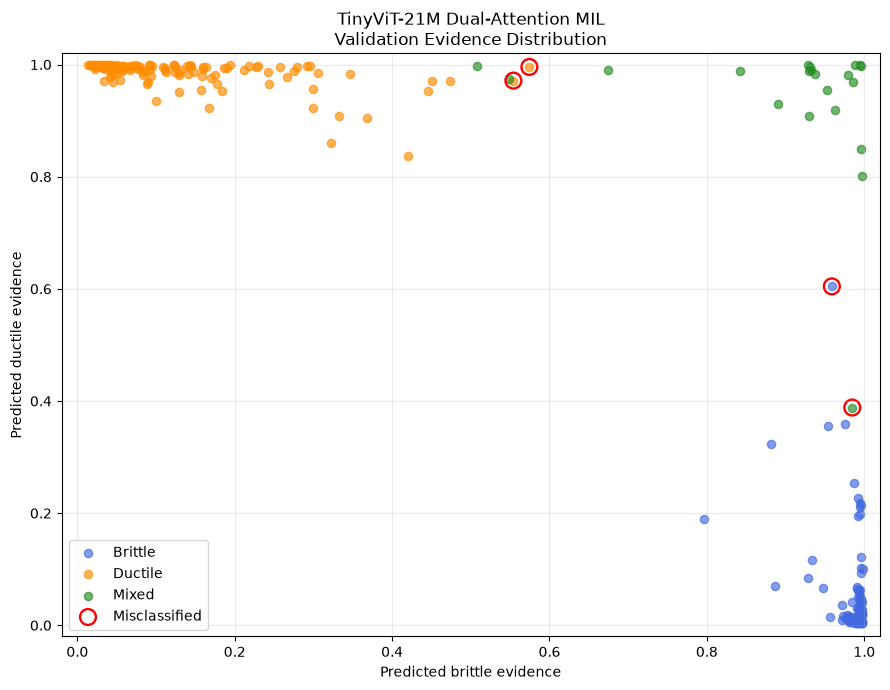


Saved: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_dual_attention_mil/validation_evidence_scores.csv

Cell 12 completed successfully.


In [12]:

# CELL 12 — EVIDENCE SCORE ANALYSIS

mil_model.eval()

evidence_rows = []

# 1. Collect evidence from all validation images
with torch.inference_mode():

    for idx, record in enumerate(val_records):

        features = val_features[
            idx:idx + 1
        ].to(DEVICE)

        logits, attention = mil_model(features)

        evidence = torch.sigmoid(
            logits
        )[0].cpu().numpy()

        probs = class_probabilities(
            logits
        )[0].cpu().numpy()

        prediction = int(probs.argmax())

        evidence_rows.append({
            "filename": record["filename"],
            "group": record["group"],
            "actual": record["label"],
            "predicted": CLASSES[prediction],
            "brittle_evidence": float(evidence[0]),
            "ductile_evidence": float(evidence[1]),
            "mixed_probability": float(probs[2]),
            "correct": (
                CLASSES[prediction] == record["label"]
            )
        })


# 2. Create evidence DataFrame
evidence_df = pd.DataFrame(evidence_rows)

assert len(evidence_df) == 280

print("VALIDATION — EVIDENCE ANALYSIS")
print("=" * 65)

print("\nAVERAGE EVIDENCE BY ACTUAL CLASS")

print(
    evidence_df.groupby("actual")[
        [
            "brittle_evidence",
            "ductile_evidence",
            "mixed_probability"
        ]
    ].mean().round(4)
)


# 3. Examine incorrect predictions
errors = evidence_df[
    ~evidence_df["correct"]
].copy()

print("\nMISCLASSIFIED IMAGES")
print("-" * 65)

print(
    errors[
        [
            "filename",
            "actual",
            "predicted",
            "brittle_evidence",
            "ductile_evidence",
            "mixed_probability"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# 4. Visualize brittle versus ductile evidence
fig, ax = plt.subplots(figsize=(9, 7))

colors = {
    "Brittle": "royalblue",
    "Ductile": "darkorange",
    "Mixed": "forestgreen"
}

for cls in CLASSES:

    subset = evidence_df[
        evidence_df["actual"] == cls
    ]

    ax.scatter(
        subset["brittle_evidence"],
        subset["ductile_evidence"],
        label=cls,
        color=colors[cls],
        alpha=0.65,
        s=35
    )

# Mark all misclassified images
ax.scatter(
    errors["brittle_evidence"],
    errors["ductile_evidence"],
    facecolors="none",
    edgecolors="red",
    s=130,
    linewidths=1.7,
    label="Misclassified"
)

ax.set_xlabel("Predicted brittle evidence")
ax.set_ylabel("Predicted ductile evidence")

ax.set_title(
    "TinyViT-21M Dual-Attention MIL\n"
    "Validation Evidence Distribution"
)

ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plot_path = (
    PLOTS_DIR / "validation_evidence_distribution.png"
)

plt.savefig(plot_path, dpi=180)
plt.show()


# 5. Save evidence scores
output_path = (
    RESULTS_DIR / "validation_evidence_scores.csv"
)

evidence_df.to_csv(
    output_path,
    index=False
)

print("\nSaved:", output_path)
print("\nCell 12 completed successfully.")


Original MIL decisions reproduced.

VALIDATION THRESHOLD COMPARISON
 threshold  accuracy  macro_f1  mixed_precision  mixed_recall  mixed_f1  false_mixed  missed_mixed
    0.5000    0.9857    0.9645           0.8696        0.9524    0.9091            3             1
    0.5500    0.9786    0.9448           0.8571        0.8571    0.8571            3             3
    0.6000    0.9857    0.9615           0.9474        0.8571    0.9000            1             3
    0.6500    0.9893    0.9706           1.0000        0.8571    0.9231            0             3
    0.7000    0.9857    0.9600           1.0000        0.8095    0.8947            0             4
    0.7500    0.9857    0.9600           1.0000        0.8095    0.8947            0             4
    0.8000    0.9857    0.9600           1.0000        0.8095    0.8947            0             4
    0.8500    0.9750    0.9245           1.0000        0.6667    0.8000            0             7

PREDICTION CHANGES: 0.50 -> 0.65
-------

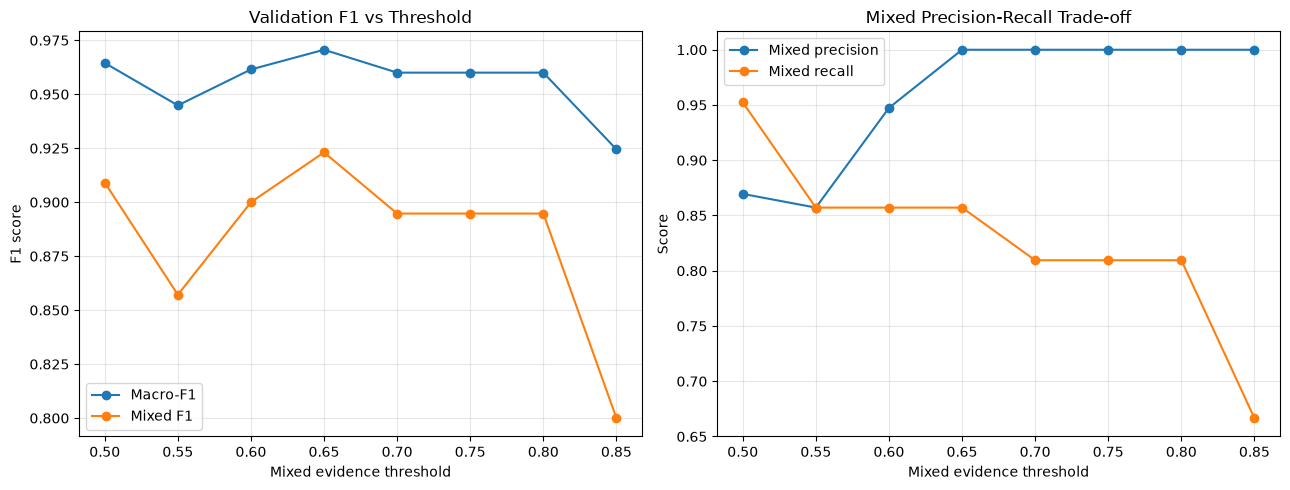


Saved: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_dual_attention_mil/threshold_sensitivity.csv

Cell 13 completed successfully.


In [14]:

# CELL 13 — MIXED DECISION THRESHOLD ANALYSIS

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# 1. Extract existing validation evidence scores
p_brittle = evidence_df[
    "brittle_evidence"
].to_numpy()

p_ductile = evidence_df[
    "ductile_evidence"
].to_numpy()

y_true_threshold = (
    evidence_df["actual"]
    .map(class_to_idx)
    .to_numpy()
)


# 2. Decision function
def predict_with_threshold(
    p_brittle,
    p_ductile,
    threshold
):

    # Both mechanisms must pass the threshold
    is_mixed = (
        (p_brittle >= threshold) &
        (p_ductile >= threshold)
    )

    # Otherwise choose the stronger mechanism
    pure_predictions = np.where(
        p_brittle >= p_ductile,
        0,
        1
    )

    return np.where(
        is_mixed,
        2,
        pure_predictions
    )


# 3. Verify threshold 0.50 reproduces original MIL
original_mil_preds = (
    evidence_df["predicted"]
    .map(class_to_idx)
    .to_numpy()
)

pred_050 = predict_with_threshold(
    p_brittle,
    p_ductile,
    0.50
)

assert np.array_equal(
    pred_050,
    original_mil_preds
), "Threshold 0.50 did not reproduce MIL predictions."

print("Original MIL decisions reproduced.")


# 4. Evaluate different thresholds
thresholds = [
    0.50, 0.55, 0.60, 0.65,
    0.70, 0.75, 0.80, 0.85
]

results = []

for threshold in thresholds:

    predictions = predict_with_threshold(
        p_brittle,
        p_ductile,
        threshold
    )

    results.append({

        "threshold": threshold,

        "accuracy": accuracy_score(
            y_true_threshold,
            predictions
        ),

        "macro_f1": f1_score(
            y_true_threshold,
            predictions,
            average="macro",
            zero_division=0
        ),

        "mixed_precision": precision_score(
            y_true_threshold,
            predictions,
            labels=[2],
            average="macro",
            zero_division=0
        ),

        "mixed_recall": recall_score(
            y_true_threshold,
            predictions,
            labels=[2],
            average="macro",
            zero_division=0
        ),

        "mixed_f1": f1_score(
            y_true_threshold,
            predictions,
            labels=[2],
            average="macro",
            zero_division=0
        ),

        "false_mixed": int(
            (
                (predictions == 2) &
                (y_true_threshold != 2)
            ).sum()
        ),

        "missed_mixed": int(
            (
                (predictions != 2) &
                (y_true_threshold == 2)
            ).sum()
        )

    })


# 5. Create comparison DataFrame
threshold_df = pd.DataFrame(results)

print("\nVALIDATION THRESHOLD COMPARISON")
print("=" * 85)

print(
    threshold_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# 6. Examine prediction changes at threshold 0.65
candidate_threshold = 0.65

candidate_preds = predict_with_threshold(
    p_brittle,
    p_ductile,
    candidate_threshold
)

changed_indices = np.where(
    candidate_preds != pred_050
)[0]

print("\nPREDICTION CHANGES: 0.50 -> 0.65")
print("-" * 85)

if len(changed_indices) == 0:
    print("No prediction changes.")

for idx in changed_indices:

    print(
        evidence_df.iloc[idx]["filename"],
        "| Actual:", evidence_df.iloc[idx]["actual"],
        "| Before:", CLASSES[pred_050[idx]],
        "| After:", CLASSES[candidate_preds[idx]],
        "| Brittle:", f"{p_brittle[idx]:.4f}",
        "| Ductile:", f"{p_ductile[idx]:.4f}"
    )


# 7. Plot threshold sensitivity
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

axes[0].plot(
    threshold_df["threshold"],
    threshold_df["macro_f1"],
    marker="o",
    label="Macro-F1"
)

axes[0].plot(
    threshold_df["threshold"],
    threshold_df["mixed_f1"],
    marker="o",
    label="Mixed F1"
)

axes[0].set_title(
    "Validation F1 vs Threshold"
)

axes[0].set_xlabel(
    "Mixed evidence threshold"
)

axes[0].set_ylabel("F1 score")
axes[0].legend()
axes[0].grid(alpha=0.3)


# 8. Mixed precision-recall trade-off
axes[1].plot(
    threshold_df["threshold"],
    threshold_df["mixed_precision"],
    marker="o",
    label="Mixed precision"
)

axes[1].plot(
    threshold_df["threshold"],
    threshold_df["mixed_recall"],
    marker="o",
    label="Mixed recall"
)

axes[1].set_title(
    "Mixed Precision-Recall Trade-off"
)

axes[1].set_xlabel(
    "Mixed evidence threshold"
)

axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plot_path = (
    PLOTS_DIR / "mil_threshold_sensitivity.png"
)

plt.savefig(
    plot_path,
    dpi=180
)

plt.show()


# 9. Save threshold analysis
output_path = (
    RESULTS_DIR / "threshold_sensitivity.csv"
)

threshold_df.to_csv(
    output_path,
    index=False
)

print("\nSaved:", output_path)

print("\nCell 13 completed successfully.")
